# 02 - Results analysis
Run `python download_data.py` and `python run_all.py` first. This notebook reads the saved results and then goes
**beyond** them: residual analysis, where the model fails, and a `log(age)` experiment.

**Where outputs go:** the cell outputs live inside this `.ipynb` file once you run and *save* it (Ctrl+S).
Figures and tables made by the analysis cells are *also* written to `results/figures/` and `results/metrics/`
so they exist as plain files.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src import config as C
from src import diagnostics as D
from src import plots
from src.data import load_split
from src.evaluate import regression_metrics
from src.results import load_comparison, load_saved_model, load_summary

X_train, X_test, y_train, y_test = load_split()
C.FIGURES_DIR.mkdir(parents=True, exist_ok=True); C.METRICS_DIR.mkdir(parents=True, exist_ok=True)
%matplotlib inline

## A. Saved results
Final comparison (hyperparameters chosen by 5-fold CV on the training set; test metrics computed once).

In [2]:
load_comparison()

,model,best_params,cv_rmse,test_rmse,test_mae,test_r2,n_features,n_nonzero
0,Lasso,"degree=4, alpha=0.02593",6.002198,6.505349,4.641076,0.858144,494,154
1,Ridge,"degree=3, alpha=0.4175",6.448129,6.266020,4.618434,0.868390,164,164
2,OLS,degree=3,7.171812,5.948420,4.502016,0.881393,164,164


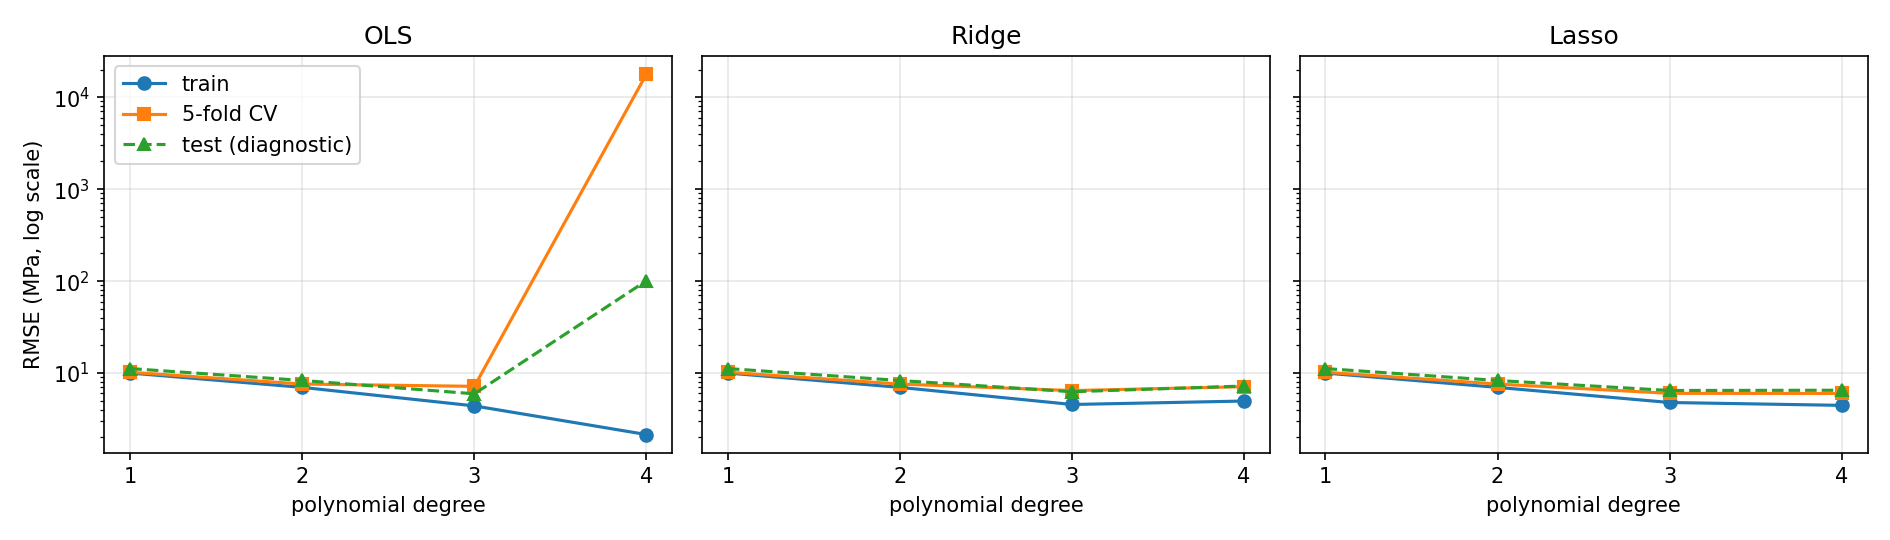

In [3]:
display(Image(str(C.FIGURES_DIR / 'degree_curves.png')))

In [4]:
for m in ['ols', 'ridge', 'lasso', 'elastic_net']:
    s = load_summary(m)
    if s:
        print(f"{m:12s} best={s['best_params']}  |  1-SE simplest={s['one_se_params']}  |  non-zero coefs: {s['n_nonzero']}/{s['n_features']}")

ols          best={'degree': 3}  |  1-SE simplest={'degree': 2}  |  non-zero coefs: 164/164
ridge        best={'degree': 3, 'alpha': 0.4175318936560405}  |  1-SE simplest={'degree': 3, 'alpha': 1.2689610031679235}  |  non-zero coefs: 164/164
lasso        best={'degree': 4, 'alpha': 0.02592943797404667}  |  1-SE simplest={'degree': 3, 'alpha': 0.02592943797404667}  |  non-zero coefs: 154/494


In [ ]:
for m in ['ridge', 'lasso']:
    display(Image(str(C.FIGURES_DIR / f'{m}_heatmap.png')))

## B. Residual analysis
A **residual** is `actual - predicted` for one sample: how many MPa the model missed by, and in which direction.
RMSE compresses all residuals into one number; residual plots show **how** the model is wrong, which tells you
whether the model is missing structure or whether the remaining error is just noise.

We use **out-of-fold predictions on the training set** (each row predicted by a model that never saw it),
so the test set is not used to make decisions.

| Panel | A healthy model looks like | Warning sign |
|---|---|---|
| Residuals vs predicted | a shapeless cloud around 0 | a **curve** (missing non-linearity) or a **funnel** (error grows with strength: non-constant variance) |
| Histogram | bell-shaped, centred at 0 | skew or long tails (outliers) |
| Q-Q plot | points close to the diagonal | tails bending away (heavy tails / outliers) |
| Residuals vs age | no pattern | a trend or bend (a missing age effect, e.g. `log(age)`) |

Best model by CV RMSE: lasso {'degree': 4, 'alpha': 0.02592943797404667}


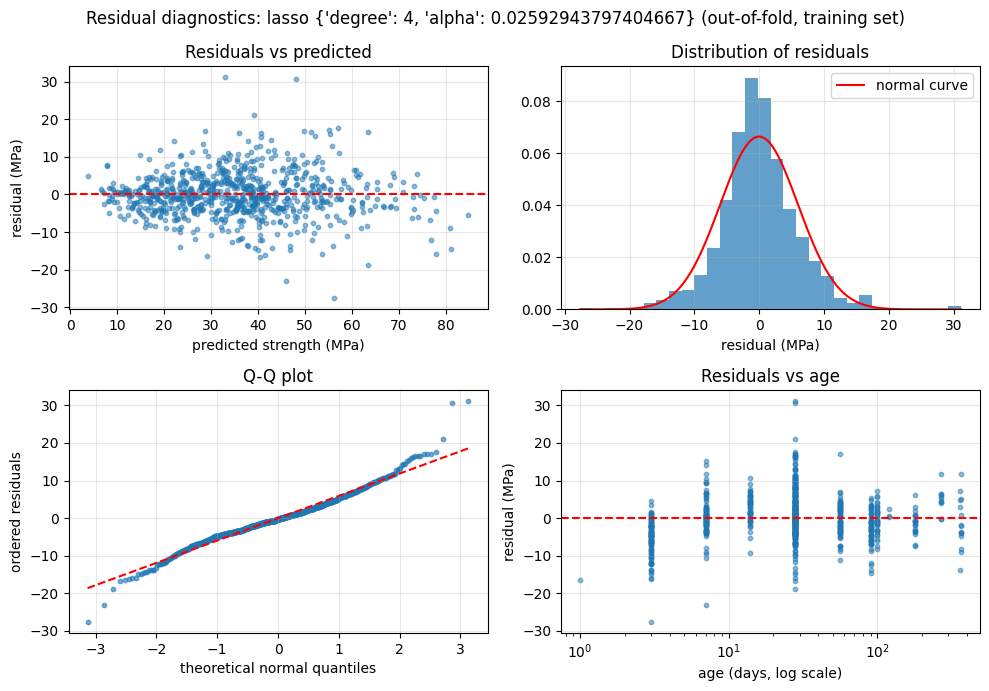

mean residual (bias): -0.018 MPa
residual std:         6.015 MPa
median |error|:       3.348 MPa
90% of errors are below 9.64 MPa


In [5]:
key, params = D.best_model()
print('Best model by CV RMSE:', key, params)
pred = D.oof_predictions(key, params, X_train, y_train)
err = D.error_frame(X_train, y_train, pred)

fig = plots.residual_diagnostics(err['predicted'], err['residual'], err['age'],
                                 title=f'Residual diagnostics: {key} {params} (out-of-fold, training set)')
fig.savefig(C.FIGURES_DIR / 'residual_diagnostics.png', dpi=150)
plt.show()

print('mean residual (bias): %.3f MPa' % err['residual'].mean())
print('residual std:         %.3f MPa' % err['residual'].std())
print('median |error|:       %.3f MPa' % err['abs_error'].median())
print('90%% of errors are below %.2f MPa' % err['abs_error'].quantile(0.9))

## C. Where does the best model fail?
Averages hide problems. Here we look at the **largest individual errors** and at error **by age** and **by true
strength**. `bias` is the mean residual: positive means the model under-predicts that group, negative means it over-predicts.

In [6]:
print('10 largest errors:')
display(err.sort_values('abs_error', ascending=False).head(10).round(2))

by_age = D.error_by_group(err, 'age')
by_strength = D.error_by_group(err, 'actual', bins=[0, 20, 30, 40, 50, 60, 100])
by_age.to_csv(C.METRICS_DIR / 'error_by_age.csv'); by_strength.to_csv(C.METRICS_DIR / 'error_by_strength.csv')
print('Error by age (days):');            display(by_age)
print('Error by true strength (MPa):');   display(by_strength)

10 largest errors:


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,actual,predicted,residual,abs_error
580,505.00,0.00,60.00,195.00,0.00,1030.0,630.00,28.0,64.02,32.88,31.13,31.13
64,451.00,0.00,0.00,165.00,11.25,1030.0,745.00,28.0,78.80,48.10,30.70,30.70
227,379.50,151.20,0.00,153.90,15.90,1134.3,605.00,3.0,28.60,56.24,-27.64,27.64
715,362.60,189.00,0.00,164.90,11.60,944.7,755.80,7.0,22.90,45.98,-23.08,23.08
87,520.00,0.00,0.00,170.00,5.20,855.0,855.00,28.0,60.28,39.13,21.15,21.15
5,312.70,144.70,0.00,127.30,8.00,999.7,822.20,28.0,44.52,63.39,-18.86,18.86
477,323.70,282.80,0.00,183.80,10.30,942.7,659.90,28.0,74.70,57.10,17.59,17.59
223,424.00,22.00,132.00,168.00,8.92,822.0,750.00,28.0,72.10,55.02,17.07,17.07
482,213.72,98.05,24.51,181.71,6.86,1065.8,785.38,28.0,45.71,28.71,17.00,17.00
23,277.19,97.82,24.46,160.70,11.19,1061.7,782.46,56.0,66.82,49.84,16.98,16.98


Error by age (days):


,n,MAE,bias (mean residual)
age,,,
1.0,1,16.485,-16.485
3.0,103,5.530,-5.214
7.0,93,3.398,0.438
14.0,50,3.682,2.587
28.0,342,4.850,1.669
56.0,69,3.537,-0.305
90.0,44,3.939,-3.023
91.0,16,4.643,-2.507
100.0,38,2.897,-0.322


Error by true strength (MPa):


,n,MAE,bias (mean residual)
actual,,,
"(0, 20]",156,3.340,-2.394
"(20, 30]",161,4.296,-2.064
"(30, 40]",207,3.783,0.078
"(40, 50]",128,4.808,1.316
"(50, 60]",91,5.209,3.083
"(60, 100]",61,7.372,3.710


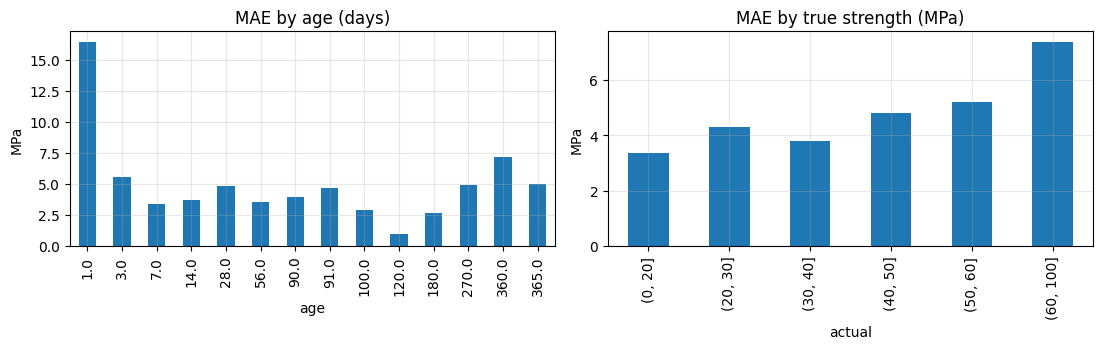

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
by_age['MAE'].plot(kind='bar', ax=axes[0], title='MAE by age (days)', ylabel='MPa')
by_strength['MAE'].plot(kind='bar', ax=axes[1], title='MAE by true strength (MPa)', ylabel='MPa')
for ax in axes: ax.grid(alpha=.3)
plt.tight_layout(); fig.savefig(C.FIGURES_DIR / 'error_breakdown.png', dpi=150); plt.show()

## D. Experiment: `log(age)` instead of raw age
Strength vs. age looks like a log curve (steep early, flat later). A polynomial in `age` can only *imitate* that bend,
so it may need a high degree. If we feed the model `log(age)` instead, a **lower** degree might do as well.

Same pipeline, same 5-fold CV on the training set, only the `age` column changes. OLS vs. Ridge (alpha tuned on a coarse grid).
Error bars are the standard deviation across folds.

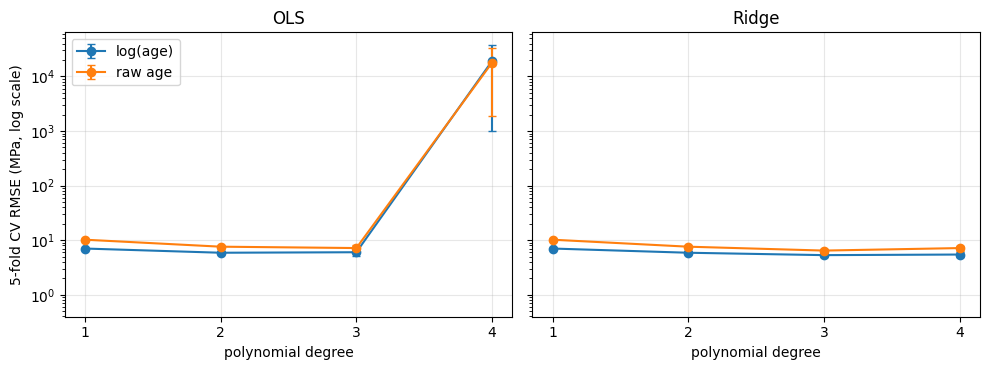

features       log(age)    raw age
model degree                      
OLS   1           7.027     10.203
      2           5.885      7.598
      3           6.013      7.172
      4       19163.843  17857.139
Ridge 1           7.027     10.203
      2           5.885      7.598
      3           5.319      6.448
      4           5.456      7.167

In [8]:
exp = D.log_age_experiment(X_train, y_train)
exp.to_csv(C.METRICS_DIR / 'log_age_experiment.csv', index=False)
fig = plots.log_age_plot(exp); fig.savefig(C.FIGURES_DIR / 'log_age_experiment.png', dpi=150); plt.show()
display(exp.pivot_table(index=['model', 'degree'], columns='features', values='cv_rmse').round(3))

## E. Final test-set check 
The test set was held out all along. This single cell reports how the *already-chosen* best model behaves on it.

In [9]:
final = load_saved_model(key)
test_pred = final.predict(X_test)
print(regression_metrics(y_test, test_pred))
test_res = np.asarray(y_test) - test_pred
print('test mean residual (bias): %.3f MPa, std %.3f MPa' % (test_res.mean(), test_res.std()))

{'rmse': 6.505348763467428, 'mae': 4.641076159102343, 'r2': 0.8581442574292415}
test mean residual (bias): 0.554 MPa, std 6.482 MPa
